In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score,
    f1_score, mean_squared_error, confusion_matrix, classification_report
)


In [ ]:
df = pd.read_csv("data/data.csv")
print("Initial Dataset Shape", df.shape)

df = df.drop(columns=[col for col in ["id", "Unnamed: 32"] if col in df.columns])
df["diagnosis"] = df["diagnosis"].map({"M": 1, "B": 0})

print("\nMissing values per column:\n", df.isnull().sum())
df = df.fillna(df.median(numeric_only=True))
print("\nCleaned Dataset Shape:", df.shape)
print("Target Class Counts:\n", df["diagnosis"].value_counts())

Initial Dataset Shape (569, 33)

Missing values per column:
 diagnosis                  0
radius_mean                0
texture_mean               0
perimeter_mean             0
area_mean                  0
smoothness_mean            0
compactness_mean           0
concavity_mean             0
concave points_mean        0
symmetry_mean              0
fractal_dimension_mean     0
radius_se                  0
texture_se                 0
perimeter_se               0
area_se                    0
smoothness_se              0
compactness_se             0
concavity_se               0
concave points_se          0
symmetry_se                0
fractal_dimension_se       0
radius_worst               0
texture_worst              0
perimeter_worst            0
area_worst                 0
smoothness_worst           0
compactness_worst          0
concavity_worst            0
concave points_worst       0
symmetry_worst             0
fractal_dimension_worst    0
dtype: int64

Cleaned Dataset Shape: (56

In [3]:
X = df.drop(columns=["diagnosis"])
y = df["diagnosis"]

X_train, X_test, y_train, y_test = train_test_split(
    X.values, y.values, test_size=0.25, random_state=42, stratify=y.values
)

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print("\nX_train_scaled shape:", X_train_scaled.shape)
print("X_test_scaled shape :", X_test_scaled.shape)


X_train_scaled shape: (426, 30)
X_test_scaled shape : (143, 30)



Feature means:
 radius_mean                 14.127292
texture_mean                19.289649
perimeter_mean              91.969033
area_mean                  654.889104
smoothness_mean              0.096360
compactness_mean             0.104341
concavity_mean               0.088799
concave points_mean          0.048919
symmetry_mean                0.181162
fractal_dimension_mean       0.062798
radius_se                    0.405172
texture_se                   1.216853
perimeter_se                 2.866059
area_se                     40.337079
smoothness_se                0.007041
compactness_se               0.025478
concavity_se                 0.031894
concave points_se            0.011796
symmetry_se                  0.020542
fractal_dimension_se         0.003795
radius_worst                16.269190
texture_worst               25.677223
perimeter_worst            107.261213
area_worst                 880.583128
smoothness_worst             0.132369
compactness_worst            0.25

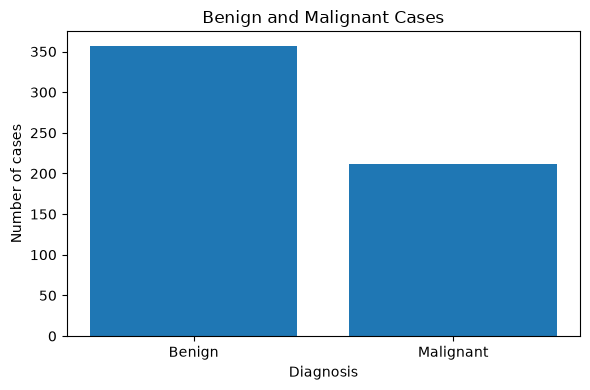

In [4]:
def run_eda(df_input):
    
    features = df_input.drop(columns=["diagnosis"], errors="ignore")
    features = features.select_dtypes(include="number")

    print("\nFeature means:\n", features.mean())
    print("\nFeature standard deviations:\n", features.std())
    print("\nFeature variances:\n", features.var())
    print("\nFeature covariance:\n", features.cov())
    print("\nFeature correlation:\n", features.corr())

    
    counts = df_input["diagnosis"].value_counts().sort_index()
    labels = ["Benign" if value == 0 else "Malignant" for value in counts.index]

    plt.figure(figsize=(6, 4))
    plt.bar(labels, counts.values)
    plt.title("Benign and Malignant Cases")
    plt.xlabel("Diagnosis")
    plt.ylabel("Number of cases")
    plt.tight_layout()
    plt.show()


run_eda(df)

In [5]:
model = LogisticRegression(max_iter=1000)
model.fit(X_train_scaled, y_train)

,"max_iter max_iter: int, default=100Maximum number of iterations taken for the solvers to converge.",1000
,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation <regularized-logistic-loss>`) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",None
,"random_state random_state: int, RandomState instance, default=NoneOnly used for `solver` == 'sag', 'saga' or 'liblinear' to shuffle thedata. It has no effect on the other solvers.See :term:`Glossary <random_state>` for details.",None
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use i

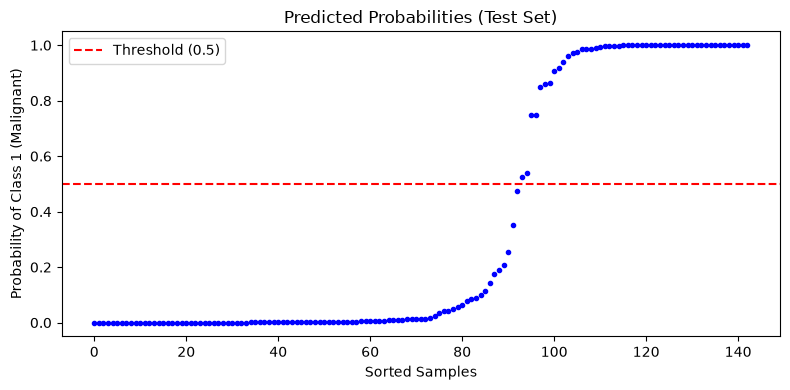

In [6]:
y_probs = model.predict_proba(X_test_scaled)[:, 1]
sorted_probs = np.sort(y_probs)

plt.figure(figsize=(8, 4))
plt.plot(sorted_probs, marker='.', linestyle='none', color='blue')
plt.axhline(0.5, color='red', linestyle='--', label='Threshold (0.5)')
plt.title('Predicted Probabilities (Test Set)')
plt.xlabel('Sorted Samples')
plt.ylabel('Probability of Class 1 (Malignant)')
plt.legend()
plt.tight_layout()
plt.show()

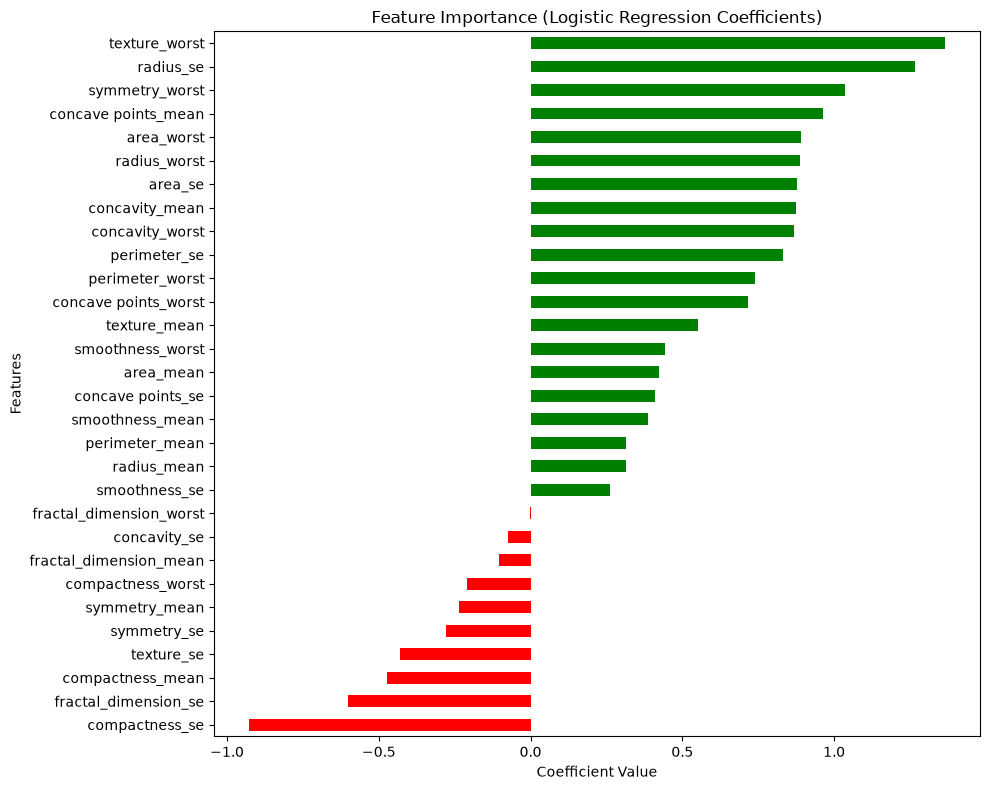

In [7]:
weights = pd.Series(model.coef_[0], index=X.columns).sort_values()

plt.figure(figsize=(10, 8))
weights.plot(kind='barh', color=np.where(weights > 0, 'green', 'red'))
plt.title('Feature Importance (Logistic Regression Coefficients)')
plt.xlabel('Coefficient Value')
plt.ylabel('Features')
plt.tight_layout()
plt.show()

In [8]:
def evaluate_model(y_train_arg, y_train_pred_arg, y_test_arg, y_test_pred_arg):
    print("\n--- Training Set Evaluation ---")
    print(f"Accuracy : {accuracy_score(y_train_arg, y_train_pred_arg):.4f}")
    print(f"Precision: {precision_score(y_train_arg, y_train_pred_arg):.4f}")
    print(f"Recall   : {recall_score(y_train_arg, y_train_pred_arg):.4f}")
    print(f"F1-Score : {f1_score(y_train_arg, y_train_pred_arg):.4f}")
    print(f"Confusion Matrix:\n{confusion_matrix(y_train_arg, y_train_pred_arg)}")

    print("\n--- Testing Set Evaluation ---")
    print(f"Accuracy : {accuracy_score(y_test_arg, y_test_pred_arg):.4f}")
    print(f"Precision: {precision_score(y_test_arg, y_test_pred_arg):.4f}")
    print(f"Recall   : {recall_score(y_test_arg, y_test_pred_arg):.4f}")
    print(f"F1-Score : {f1_score(y_test_arg, y_test_pred_arg):.4f}")
    print(f"Confusion Matrix:\n{confusion_matrix(y_test_arg, y_test_pred_arg)}")
    print("\nClassification Report:\n", classification_report(y_test_arg, y_test_pred_arg))


y_train_pred = model.predict(X_train_scaled)
y_test_pred = model.predict(X_test_scaled)

evaluate_model(y_train, y_train_pred, y_test, y_test_pred)


--- Training Set Evaluation ---
Accuracy : 0.9883
Precision: 1.0000
Recall   : 0.9686
F1-Score : 0.9840
Confusion Matrix:
[[267   0]
 [  5 154]]

--- Testing Set Evaluation ---
Accuracy : 0.9650
Precision: 0.9800
Recall   : 0.9245
F1-Score : 0.9515
Confusion Matrix:
[[89  1]
 [ 4 49]]

Classification Report:
               precision    recall  f1-score   support

           0       0.96      0.99      0.97        90
           1       0.98      0.92      0.95        53

    accuracy                           0.97       143
   macro avg       0.97      0.96      0.96       143
weighted avg       0.97      0.97      0.96       143

